## Importer les packages

In [14]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import keras
from keras.models import Sequential # permet de créer l'architecture reseaux neurones
from keras.layers import Dense # permet de créer une couche

## Importer les données

#### Description des variables du jeu de données "Bank Marketing"

Ce jeu de données contient des informations issues de campagnes de marketing téléphonique réalisées par une banque portugaise. L'objectif est de prédire si un client souscrira à un dépôt à terme (`y`).

| Variable           | Type          | Description |
|--------------------|---------------|-------------|
| `age`              | Numérique     | Âge du client (en années). |
| `job`              | Catégorielle  | Profession du client (ex. : 'admin.', 'technician', 'services', etc.). |
| `marital`          | Catégorielle  | Statut marital du client (ex. : 'married', 'single', 'divorced'). |
| `education`        | Catégorielle  | Niveau d'éducation du client (ex. : 'basic.4y', 'high.school', 'university.degree'). |
| `default`          | Binaire       | Le client a-t-il un crédit en défaut ? ('yes', 'no'). |
| `housing`          | Binaire       | Le client a-t-il un prêt immobilier ? ('yes', 'no'). |
| `loan`             | Binaire       | Le client a-t-il un prêt personnel ? ('yes', 'no'). |
| `contact`          | Catégorielle  | Type de contact utilisé pour la communication ('cellular', 'telephone'). |
| `month`            | Catégorielle  | Mois du dernier contact client (ex. : 'may', 'aug', 'nov'). |
| `day_of_week`      | Catégorielle  | Jour de la semaine du dernier contact (ex. : 'mon', 'tue', ...). |
| `duration`         | Numérique     | Durée du dernier contact (en secondes). **Important : cette variable est très corrélée à la cible `y`**. |
| `campaign`         | Numérique     | Nombre de contacts effectués durant cette campagne. |
| `pdays`            | Numérique     | Nombre de jours depuis le dernier contact d'une campagne précédente (999 signifie "jamais contacté auparavant"). |
| `previous`         | Numérique     | Nombre de contacts effectués avant cette campagne. |
| `poutcome`         | Catégorielle  | Résultat de la campagne marketing précédente ('success', 'failure', 'nonexistent'). |
| `y`                | Cible (binaire) | Le client a-t-il souscrit à un dépôt à terme ? ('yes', 'no'). |


In [15]:
# Monter le drive
#from google.colab import drive
#drive.mount('/content/drive')

In [16]:
# Importer les données
df = pd.read_csv('banking_dataset.csv')
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,y
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,210,1,999,0,nonexistent,no
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,138,1,999,0,nonexistent,no
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,339,3,6,2,success,yes
3,39,services,married,high.school,no,no,no,cellular,apr,fri,185,2,999,0,nonexistent,no
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,137,1,3,1,success,yes


In [17]:
# rénommer la variable y
df.rename(columns = {'y': 'souscription'}, inplace = True)
df.head()

C:\Users\EL MOUSSA\AppData\Local\Temp\ipykernel_6988\3792958265.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns = {'y': 'souscription'}, inplace = True)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,souscription
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,210,1,999,0,nonexistent,no
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,138,1,999,0,nonexistent,no
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,339,3,6,2,success,yes
3,39,services,married,high.school,no,no,no,cellular,apr,fri,185,2,999,0,nonexistent,no
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,137,1,3,1,success,yes


In [18]:
# dimension des données
df.shape

(41188, 16)

## Exploration des données

In [19]:
# Afficher les infos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   age           41188 non-null  int64
 1   job           41188 non-null  str  
 2   marital       41188 non-null  str  
 3   education     41188 non-null  str  
 4   default       41188 non-null  str  
 5   housing       41188 non-null  str  
 6   loan          41188 non-null  str  
 7   contact       41188 non-null  str  
 8   month         41188 non-null  str  
 9   day_of_week   41188 non-null  str  
 10  duration      41188 non-null  int64
 11  campaign      41188 non-null  int64
 12  pdays         41188 non-null  int64
 13  previous      41188 non-null  int64
 14  poutcome      41188 non-null  str  
 15  souscription  41188 non-null  str  
dtypes: int64(5), str(11)
memory usage: 5.0 MB


In [20]:
# sélection les variables quantitatives
quant_data = df.select_dtypes(include = 'number')
# sélection les variables catégorielles (la cible 'souscription' en fait partie)
cat_data = df.select_dtypes(exclude = 'number')
cat_data.head()

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,souscription
0,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,nonexistent,no
1,technician,married,unknown,no,no,no,cellular,nov,fri,nonexistent,no
2,management,single,university.degree,no,yes,no,cellular,jun,thu,success,yes
3,services,married,high.school,no,no,no,cellular,apr,fri,nonexistent,no
4,retired,married,basic.4y,no,yes,no,cellular,aug,fri,success,yes


In [21]:
# décrire les variable catégorielles
cat_data.describe().T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


In [22]:
# fonction de countplot
def countplot_func(col):
  plt.figure(figsize=(10,3))
  sns.countplot(x=df[col], hue=df[col], palette='husl', legend=False) # compter les nombres d'observations dans chaque classe
  plt.xticks(rotation=45)
  plt.show()

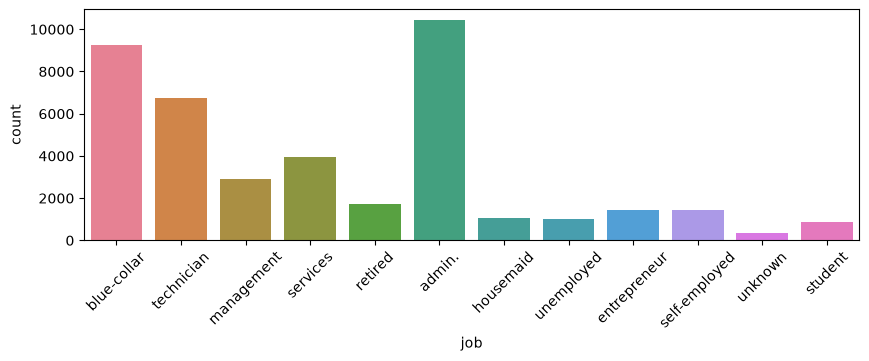

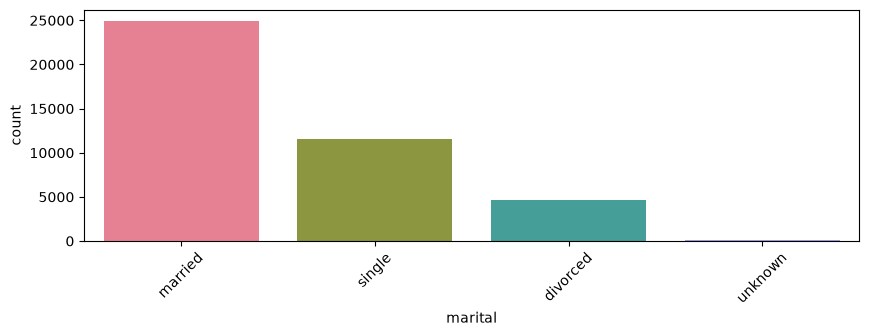

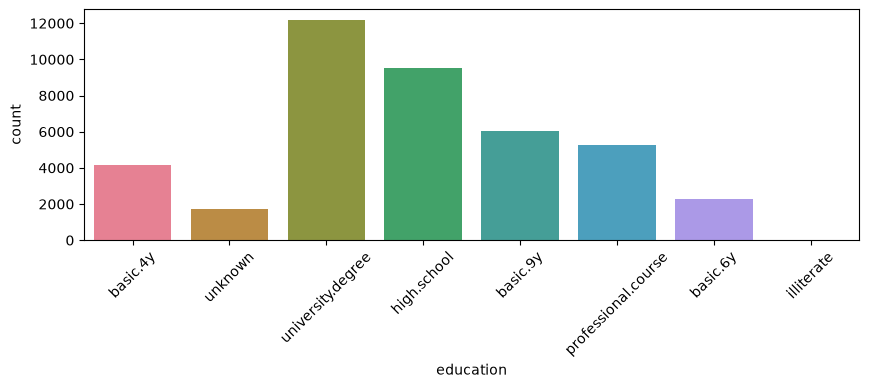

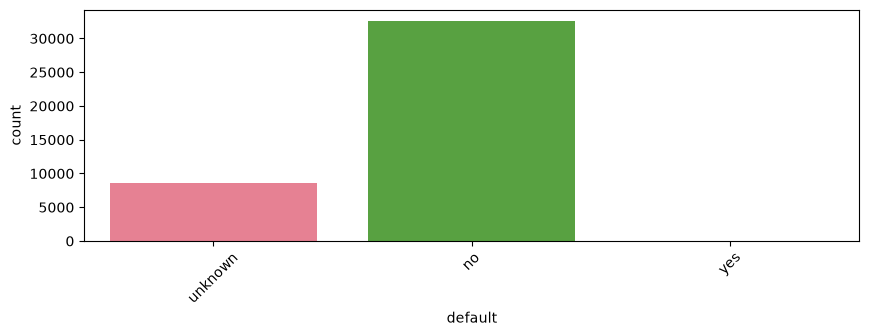

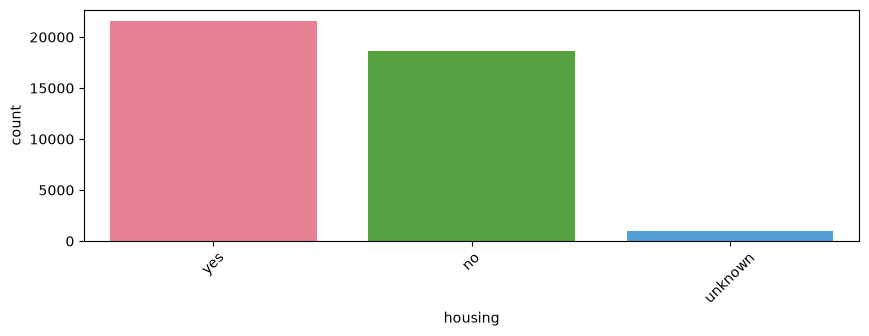

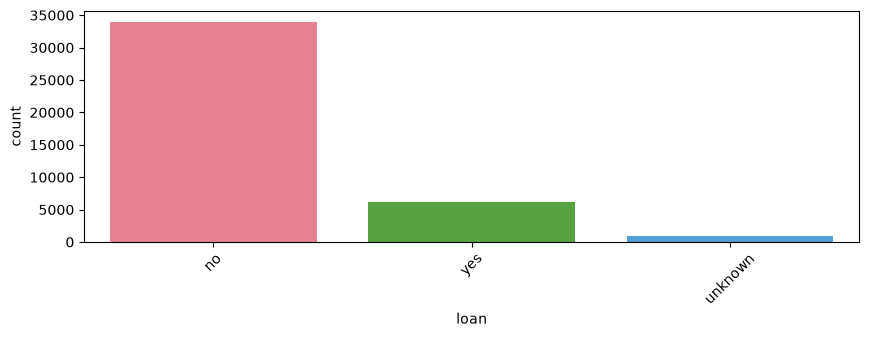

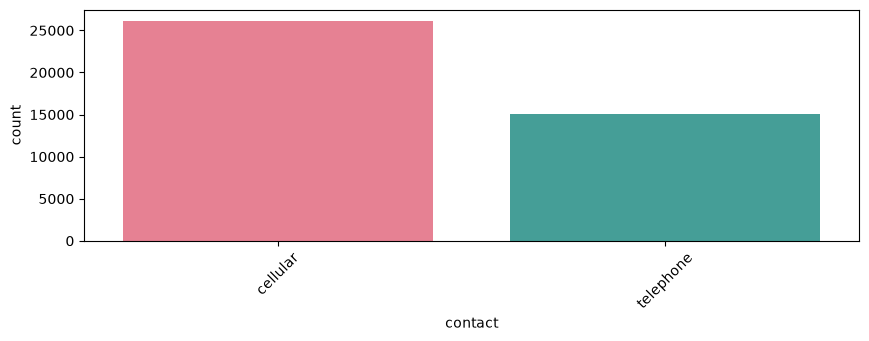

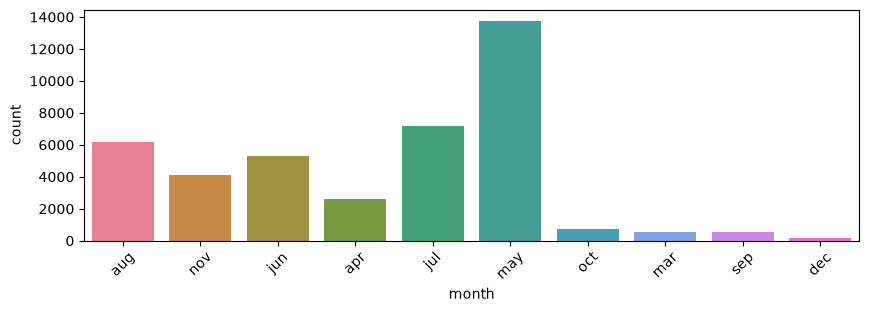

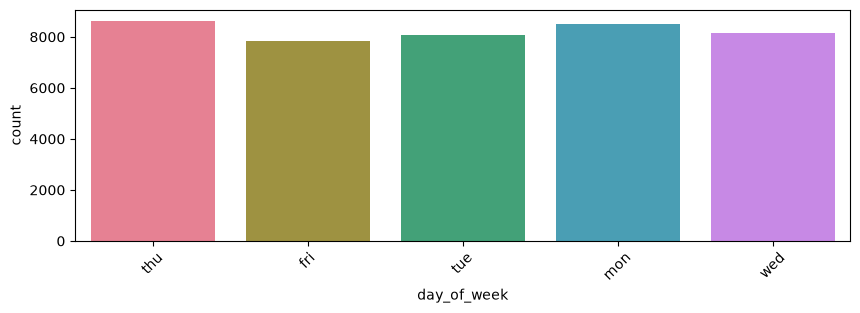

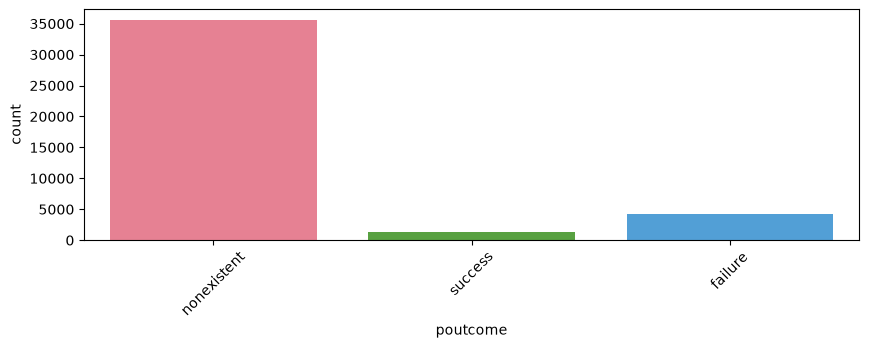

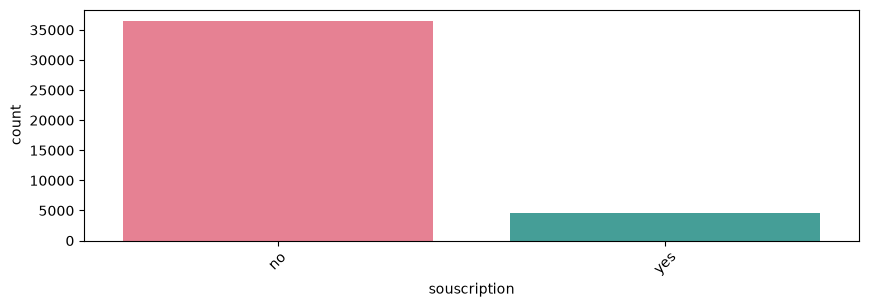

In [23]:
# visualiser les countplots
for col in cat_data.columns:
  countplot_func(col)

In [24]:
# sauvegarder les valeurs uniques de chaque variable catégorielle (avant l'encodage) en utilisant joblib
# dictionnaire {nom de la variable : liste de ses valeurs}, utilisé pour les Dropdown de l'application Streamlit
uniques = {}
for col in cat_data.columns:
  uniques[col] = np.unique(df[col]).tolist()
# sauvegarder le dictionnaire uniques
joblib.dump(uniques, 'uniques.joblib')
uniques

{'job': ['admin.',
  'blue-collar',
  'entrepreneur',
  'housemaid',
  'management',
  'retired',
  'self-employed',
  'services',
  'student',
  'technician',
  'unemployed',
  'unknown'],
 'marital': ['divorced', 'married', 'single', 'unknown'],
 'education': ['basic.4y',
  'basic.6y',
  'basic.9y',
  'high.school',
  'illiterate',
  'professional.course',
  'university.degree',
  'unknown'],
 'default': ['no', 'unknown', 'yes'],
 'housing': ['no', 'unknown', 'yes'],
 'loan': ['no', 'unknown', 'yes'],
 'contact': ['cellular', 'telephone'],
 'month': ['apr',
  'aug',
  'dec',
  'jul',
  'jun',
  'mar',
  'may',
  'nov',
  'oct',
  'sep'],
 'day_of_week': ['fri', 'mon', 'thu', 'tue', 'wed'],
 'poutcome': ['failure', 'nonexistent', 'success'],
 'souscription': ['no', 'yes']}

In [25]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.0,32.0,38.0,47.0,98.0
duration,41188.0,258.285010,259.279249,0.0,102.0,180.0,319.0,4918.0
campaign,41188.0,2.567593,2.770014,1.0,1.0,2.0,3.0,56.0
pdays,41188.0,962.475454,186.910907,0.0,999.0,999.0,999.0,999.0
previous,41188.0,0.172963,0.494901,0.0,0.0,0.0,0.0,7.0


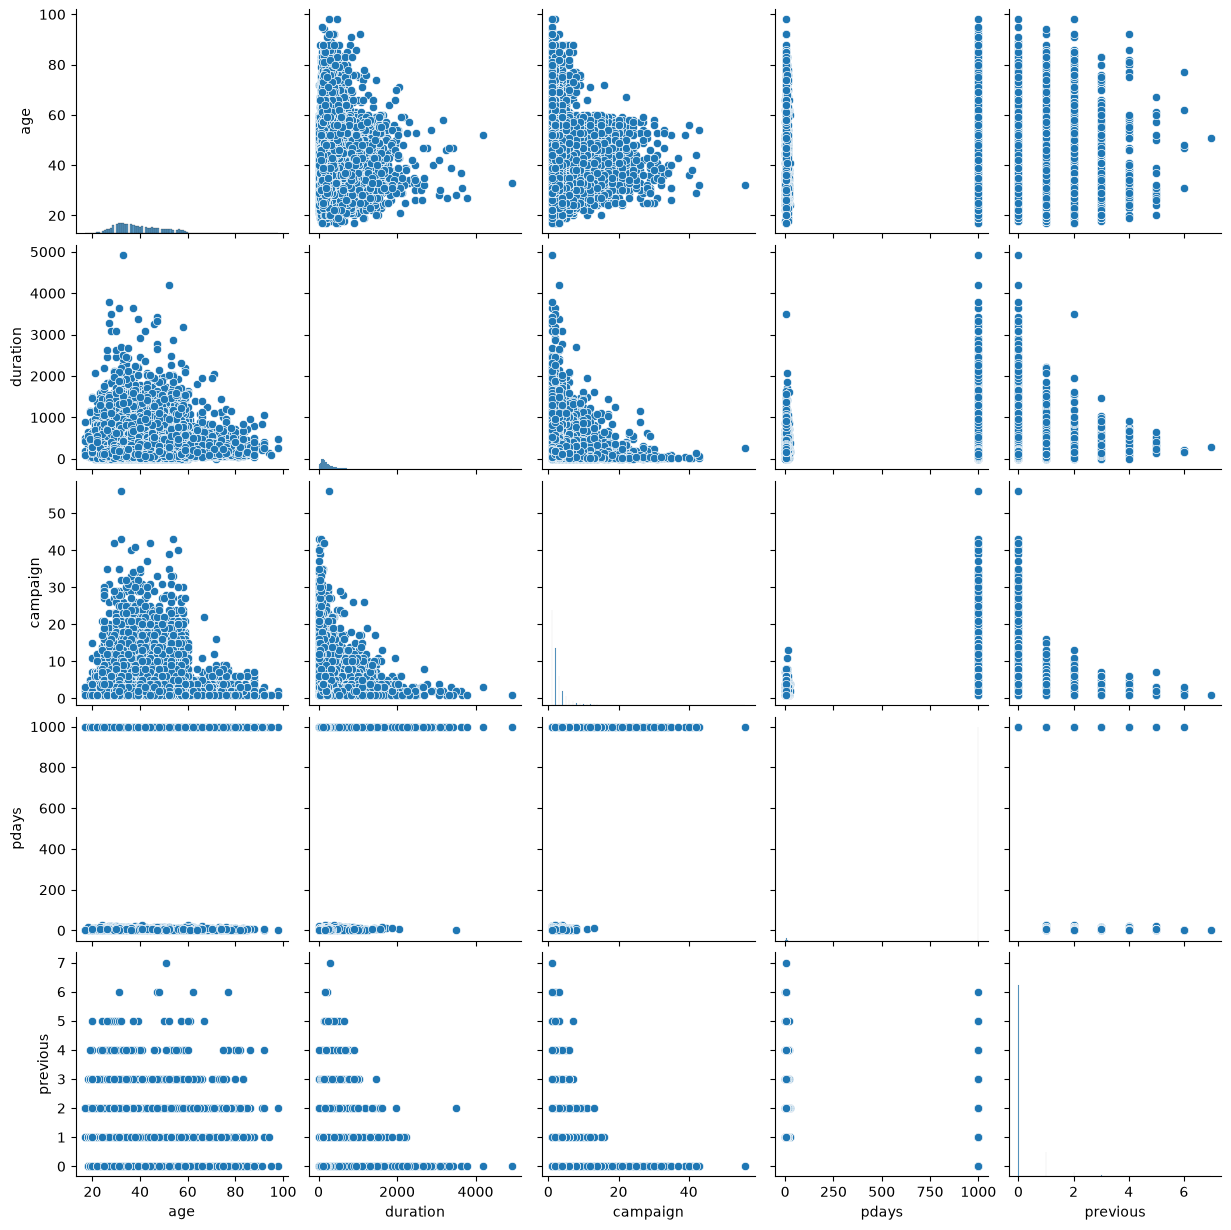

In [26]:
# pairplot des données
sns.pairplot(quant_data)
plt.show()

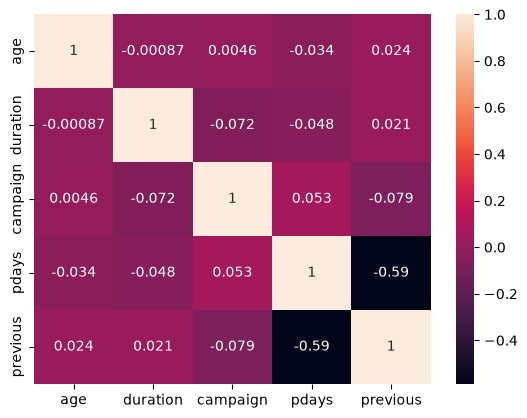

In [27]:
# matrice corrélation
sns.heatmap(quant_data.corr(), annot= True )
plt.show()

In [28]:
# fonction boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

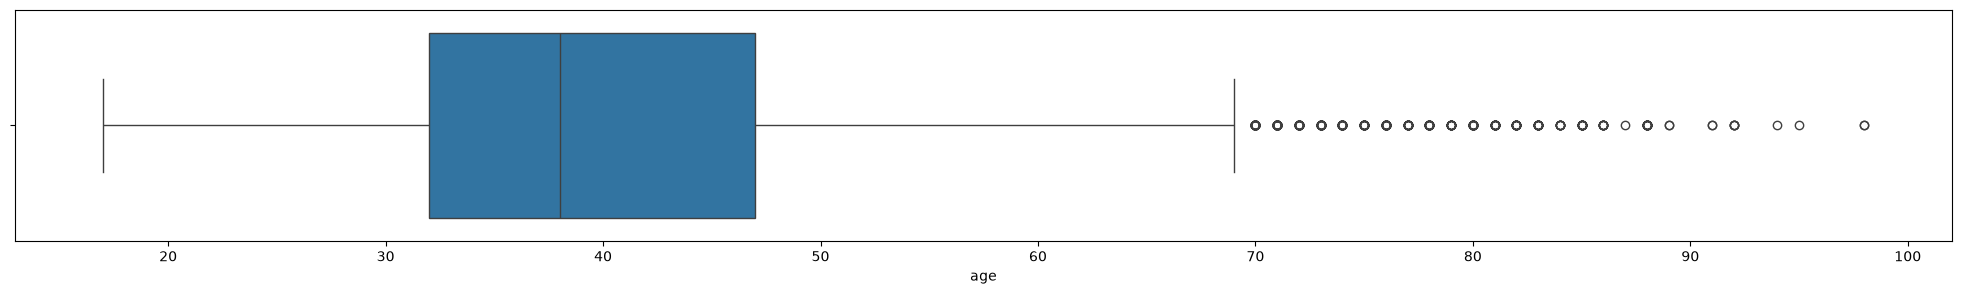

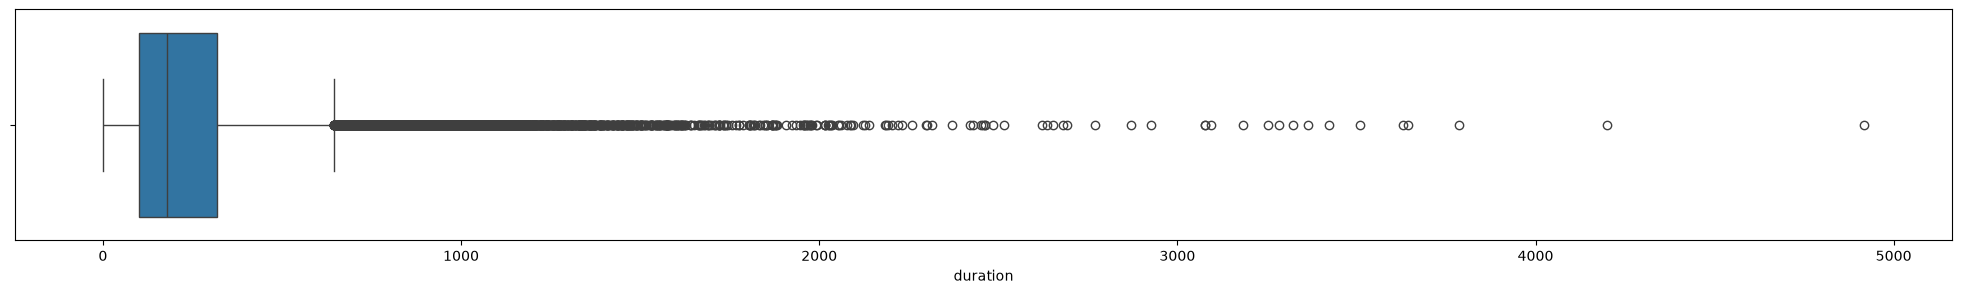

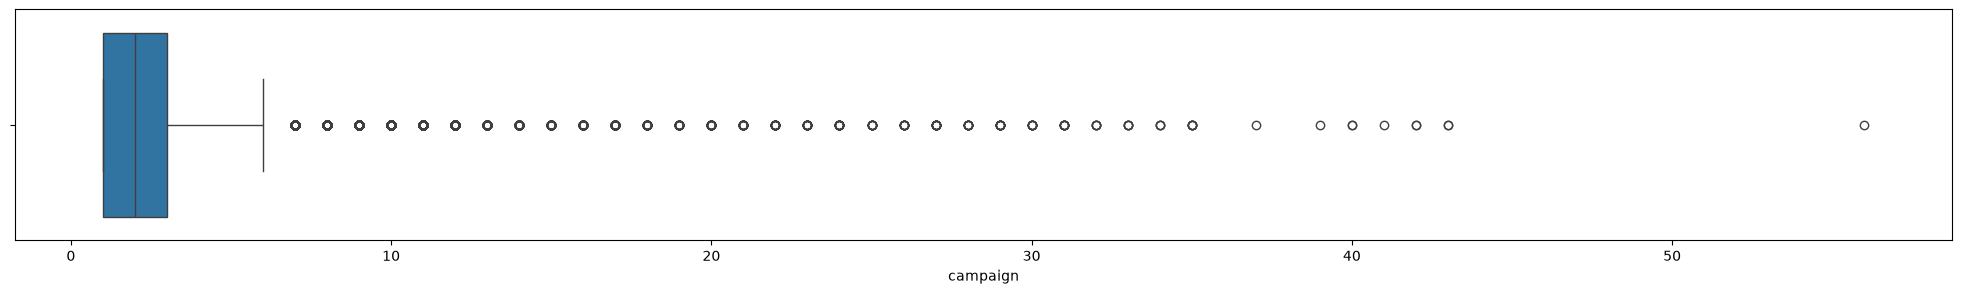

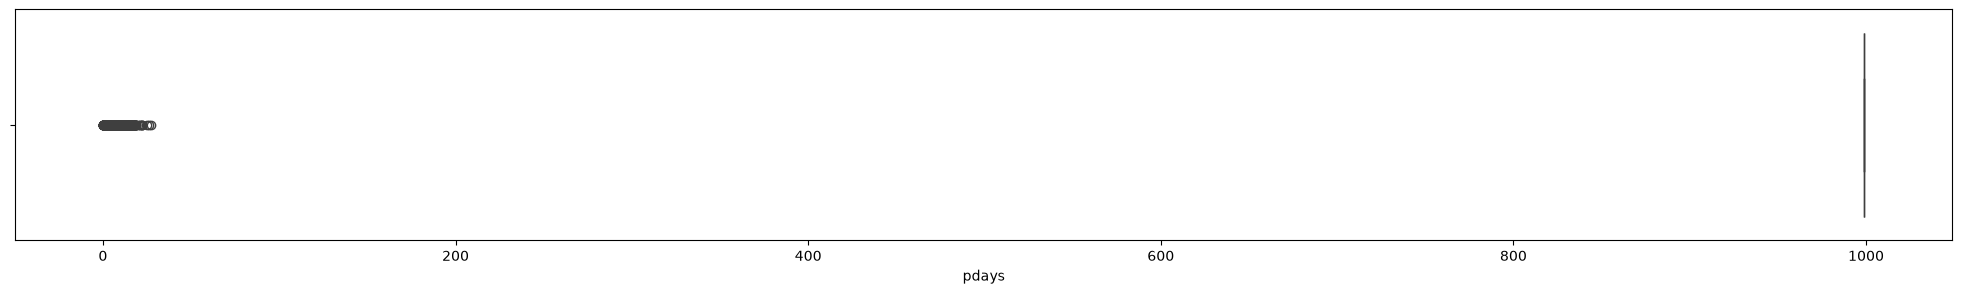

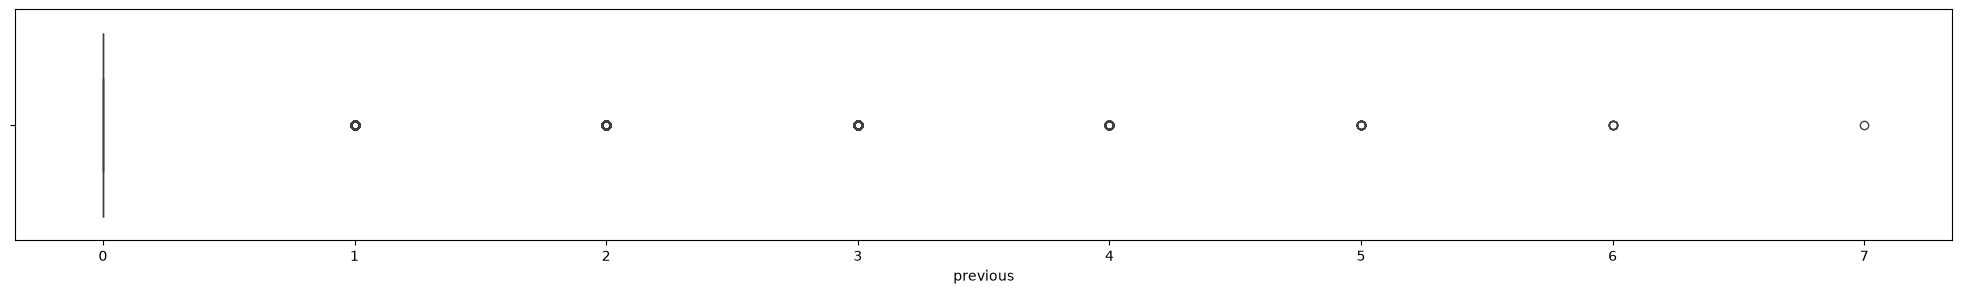

In [29]:
# boxplots des toutes les variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

## Préparation des données

In [31]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder

for col in cat_data.columns:
  encoder = LabelEncoder()
  encoder.fit(df[col])
  df[col] = encoder.transform(df[col])
  # télécharger l'encodeur
  joblib.dump(encoder, f'{col}_encoder.joblib')

df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,souscription
0,44,1,1,0,1,2,0,0,1,2,210,1,999,0,1,0
1,53,9,1,7,0,0,0,0,7,0,138,1,999,0,1,0
2,28,4,2,6,0,2,0,0,4,2,339,3,6,2,2,1
3,39,7,1,3,0,0,0,0,0,0,185,2,999,0,1,0
4,55,5,1,0,0,2,0,0,1,0,137,1,3,1,2,1


In [32]:
# Fonction d'imputation des valeurs aberrantes en utilisant le modèle KNN
from sklearn.impute import KNNImputer
def imputation_func(df, col, n_neighbors=5):
    # Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # la colonne est convertie en float pour pouvoir contenir des valeurs manquantes (NaN)
    df[col] = df[col].astype(float)
    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [33]:
# imputer les valeurs aberrantes sur les variables  (age, duration, campaign )
for col in quant_data.columns[:-2]:
    imputation_func(df,col)

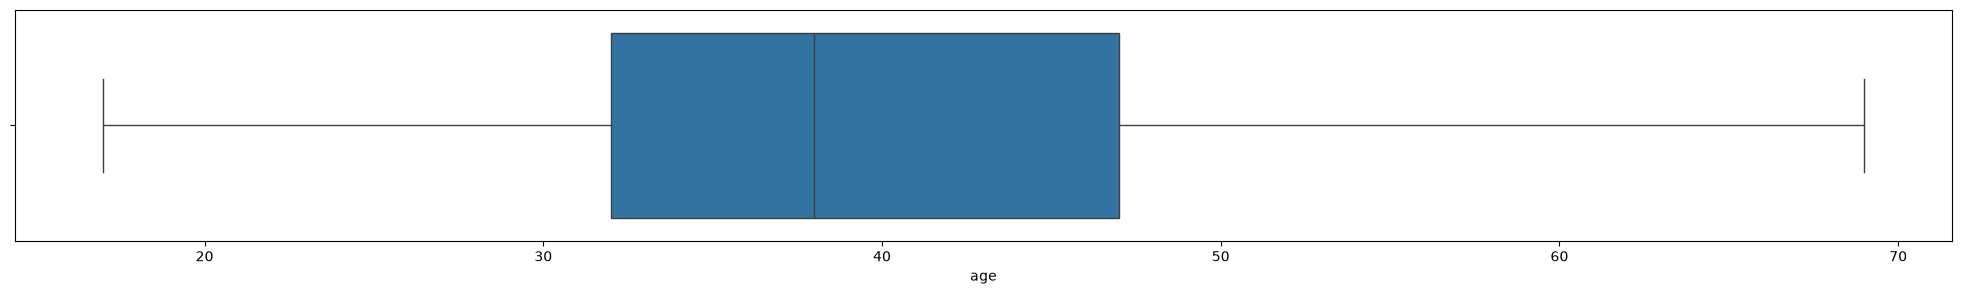

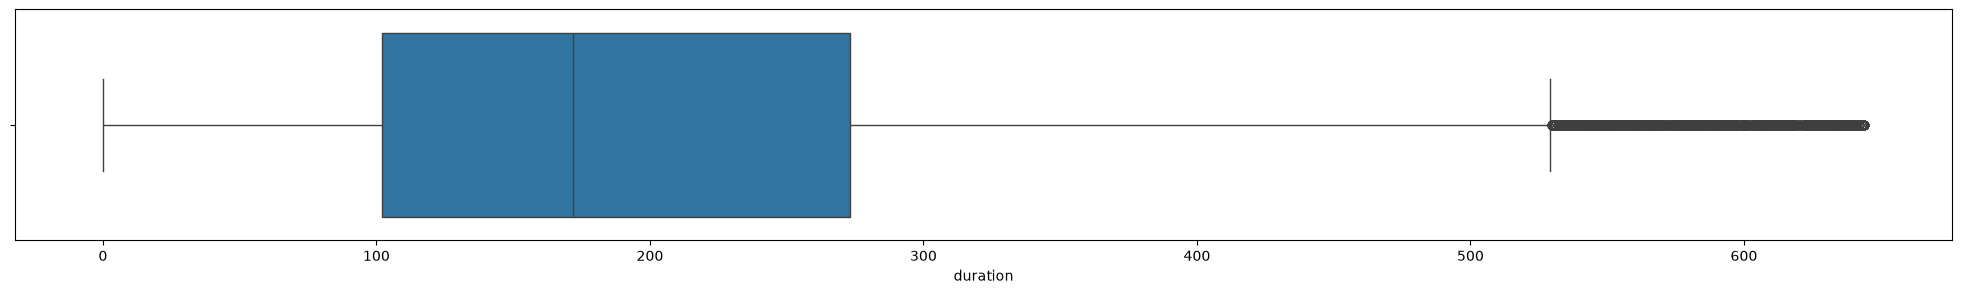

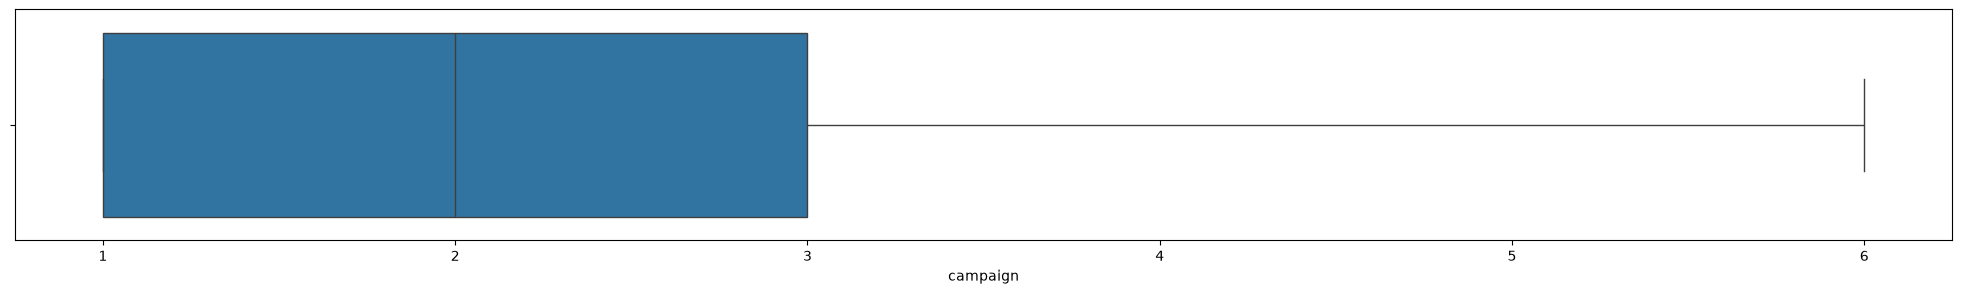

In [34]:
# réafficher les boxplots
for col in quant_data.columns[:-2]:
  boxplot_func(col)

In [35]:
# Fractionner les données : x = variables explicatives, y = cible (souscription)
x = df.drop('souscription', axis = 1).values
y = df['souscription'].values.astype(int)

In [36]:
# Normaliser les données
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)
# télécharger le scaler
joblib.dump(scaler, 'scaler.joblib')

['scaler.joblib']

In [37]:
# Splitter les données : 80% train, 10% validation, 10% test
from sklearn.model_selection import train_test_split
x_train, x_vt ,y_train, y_vt = train_test_split(x, y, test_size = 0.2, random_state = 42)
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)
x_train.shape, x_val.shape, x_test.shape

((32950, 15), (4119, 15), (4119, 15))

## Recherche des hyperparamètres optimaux avec Keras Tuner

Hyperparamètres recherchés :
- le nombre de neurones des trois couches cachées : de 32 à 512 avec un pas de 32 ;
- la fonction d'activation de chaque couche cachée : `relu` ou `tanh`.

La classe `souscription` est déséquilibrée (environ 11 % de `yes`) : en plus de l'accuracy, on suit la **precision** et le **recall**. L'objectif du tuner est `val_accuracy`.

In [38]:
# Installer keras tuner
!pip install keras-tuner --upgrade

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 2.7 MB/s eta 0:00:01
   -------- ------------------------------- 0.5/2.4 MB 2.7 MB/s eta 0:00:01
   ----------------- ---------------------- 1.0/2.4 MB 1.8 MB/s eta 0:00:01
   -------------------------- ------------- 1.6/2.4 MB 1.8 MB/s eta 0:00:01
   ---------------------------------- ----- 2.1/2.4 MB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 2.0 MB/s  0:00:01

   ---------------------------------------- 0/3 [kt-legacy]
   ---------------------------------------- 0/3 [kt-legacy]
   ------------- -------------------------- 1/3 [keras]
   ------------- -------------------------- 1/3 [keras]
   ------------- -------------------------- 1/3 [keras]
   ------------- -------------------------- 1/3 [keras]
   ------------- -------------------------- 1/3 [keras]
   -----


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
# importer le package keras_tuner
import keras_tuner as kt

# fonction build_model
def build_model(hp):
  model = Sequential() # initialiser l'architecture DNN

  # Choisir le nombre de neurones optimal pour les couches cachées entre 32 et 512
  # avec un pas de 32
  hp_units1 = hp.Int('units1', min_value=32, max_value=512, step=32)
  hp_units2 = hp.Int('units2', min_value=32, max_value=512, step=32)
  hp_units3 = hp.Int('units3', min_value=32, max_value=512, step=32)
  # Choisir la fonction d'activation optimale pour les couches cachées
  hp_activation1 = hp.Choice('activation_func1', values = ['relu', 'tanh'])
  hp_activation2 = hp.Choice('activation_func2', values = ['relu', 'tanh'])
  hp_activation3 = hp.Choice('activation_func3', values = ['relu', 'tanh'])
  # Ajouter les couches cachées
  model.add(Dense(units=hp_units1, activation=hp_activation1, input_shape = (x_train.shape[1], )))
  model.add(Dense(units=hp_units2, activation=hp_activation2))
  model.add(Dense(units=hp_units3, activation=hp_activation3))
  # couche de sortie : 1 neurone et sigmoid (classification binaire)
  model.add(Dense(1, activation='sigmoid'))

  # compiler le modèle
  model.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy', 'precision', 'recall'])

  return model

In [41]:
# Initialiser le tuner
tuner = kt.Hyperband(build_model,
                     objective='val_accuracy',   # on optimise l'accuracy sur les données de validation
                     max_epochs=10,
                     directory='tuner_dir',
                     project_name='dnn_bank',
                     overwrite=True)

# lancer la recherche avec le tuner
tuner.search(x_train, y_train, validation_data = (x_val, y_val), epochs = 10)

Trial 30 Complete [00h 03m 44s]
val_accuracy: 0.9016751646995544

Best val_accuracy So Far: 0.90288907289505
Total elapsed time: 00h 30m 40s


In [42]:
# Afficher les paramètres optimaux
best_hps = tuner.get_best_hyperparameters()[0]
for h_param in [f"units{i}" for i in range(1,4)] + [f'activation_func{i}' for i in range(1,4)]:
  print(h_param, best_hps.get(h_param))

units1 256
units2 192
units3 32
activation_func1 tanh
activation_func2 tanh
activation_func3 tanh


### Modélisation

Le modèle final est construit avec les hyperparamètres trouvés par le tuner (`best_hps`), sans valeurs écrites à la main.

In [43]:
# Définir le modèle DNN avec les hyperparamètres optimaux
from keras.callbacks import EarlyStopping
model = Sequential([
     # couche d'entrée avec units1 neurones et activation_func1 comme fonction d'activation
     Dense(units = best_hps.get('units1'), activation = best_hps.get('activation_func1'), input_shape = (x_train.shape[1], )),
     # première couche cachée avec units2 neurones et activation_func2 comme fonction d'activation
     Dense(units = best_hps.get('units2'), activation = best_hps.get('activation_func2')),
     # deuxième couche cachée avec units3 neurones et activation_func3 comme fonction d'activation
     Dense(units = best_hps.get('units3'), activation = best_hps.get('activation_func3')),
     # couche de sortie 1 neurone et sigmoid comme fonction d'activation
     Dense(units=1, activation = 'sigmoid')
     ])

# compiler le modèle
model.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy', 'precision', 'recall'])

# Définir le early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3)

# Entrainer le modèle
history = model.fit(x_train, y_train, validation_data = (x_val, y_val), epochs = 50, batch_size = 64, callbacks = early_stopping)

Epoch 1/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8949 - loss: 0.2959 - precision: 0.5936 - recall: 0.2015 - val_accuracy: 0.9002 - val_loss: 0.2795 - val_precision: 0.6071 - val_recall: 0.2282
Epoch 2/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8975 - loss: 0.2836 - precision: 0.6366 - recall: 0.2023 - val_accuracy: 0.9002 - val_loss: 0.2779 - val_precision: 0.6071 - val_recall: 0.2282
Epoch 3/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8977 - loss: 0.2817 - precision: 0.6381 - recall: 0.2031 - val_accuracy: 0.9000 - val_loss: 0.2774 - val_precision: 0.6023 - val_recall: 0.2304
Epoch 4/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8977 - loss: 0.2803 - precision: 0.6376 - recall: 0.2037 - val_accuracy: 0.8997 - val_loss: 0.2771 - val_precision: 0.5988 - val_recall: 0.2304
Epoch 5/50
515/515 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8977 - loss: 0.2791 - precision: 0.6384 - recall: 0.2034 - val_accuracy: 0.9002 - val_loss: 0

In [44]:
# télécharger le modèle
model.save('DNN_model.h5')
model.save('DNN_model.keras')

### Evaluation du modèle

In [45]:
# Erreur, accuracy, precision et recall sur les données de validation
val_metrics = model.evaluate(x_val, y_val)
print(f'Loss : {val_metrics[0]} --- Accuracy : {val_metrics[1]} --- Precision : {val_metrics[2]} --- Recall : {val_metrics[3]}')

129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9017 - loss: 0.2665 - precision: 0.5778 - recall: 0.3490
Loss : 0.26651617884635925 --- Accuracy : 0.9016751646995544 --- Precision : 0.5777778029441833 --- Recall : 0.34899330139160156


In [46]:
# Erreur, accuracy, precision et recall sur les données d'entrainement
train_metrics = model.evaluate(x_train, y_train)
print(f'Loss : {train_metrics[0]} --- Accuracy : {train_metrics[1]} --- Precision : {train_metrics[2]} --- Recall : {train_metrics[3]}')

1030/1030 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9035 - loss: 0.2488 - precision: 0.6361 - recall: 0.3262
Loss : 0.24882765114307404 --- Accuracy : 0.9034597873687744 --- Precision : 0.6360759735107422 --- Recall : 0.3262104392051697


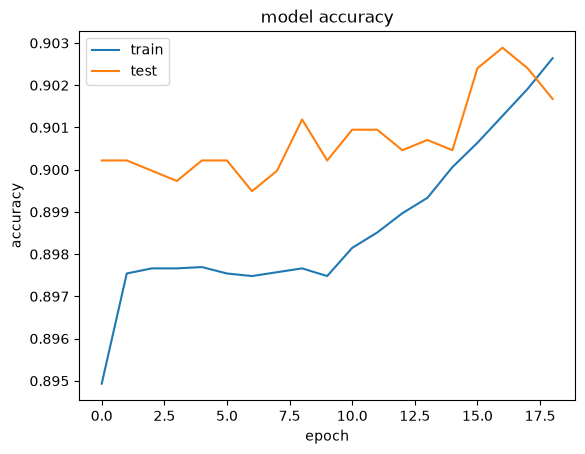

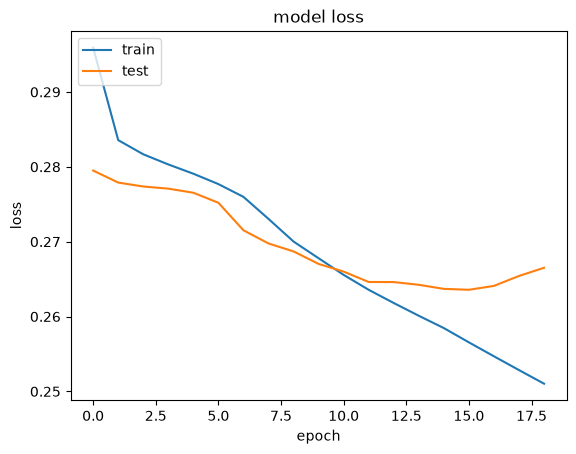

In [47]:
# plotter les accuracy et erreurs sur les données d'entrainement suivant les différents epochs
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()
# plotter les accuracy et erreurs sur les données de validation suivant les différents epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [48]:
# Erreur, accuracy, precision et recall sur les données test
test_metrics = model.evaluate(x_test, y_test)
print(f'Loss : {test_metrics[0]} --- Accuracy : {test_metrics[1]} --- Precision : {test_metrics[2]} --- Recall : {test_metrics[3]}')

129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8939 - loss: 0.2767 - precision: 0.6065 - recall: 0.3387
Loss : 0.2767159938812256 --- Accuracy : 0.89390629529953 --- Precision : 0.6064981818199158 --- Recall : 0.33870968222618103


129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


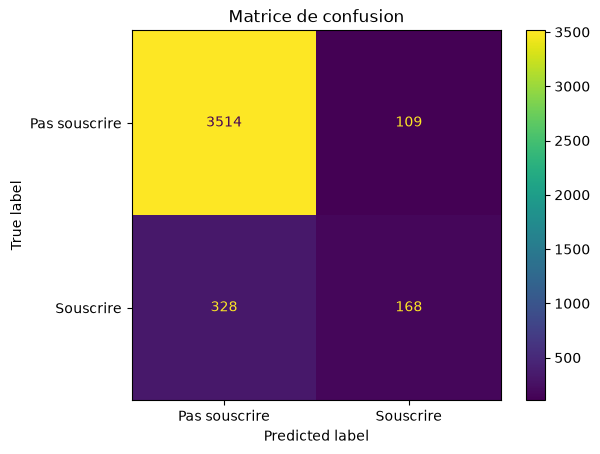

In [49]:
# matrice de confusion sur les données test
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_test_pred = (model.predict(x_test) > 0.5).astype(int).ravel()
cnf_matr = confusion_matrix(y_test, y_test_pred, labels=[0,1])
disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr, display_labels=['Pas souscrire','Souscrire'])
disp.plot()
plt.title('Matrice de confusion')
plt.show()

In [50]:
# faire un loading du modèle
from keras.models import load_model
model = load_model('DNN_model.h5')

In [51]:
# Tester le modèle avec quelques données test
y_pred_10 = np.round(model.predict(x_test[:10])).ravel()
# afficher les prédictions et les vraies valeurs
for i in range(10):
  print(f'Prédiction {i+1} : {int(y_pred_10[i])} -- Vrai : {int(y_test[i])}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
Prédiction 1 : 0 -- Vrai : 0
Prédiction 2 : 0 -- Vrai : 0
Prédiction 3 : 0 -- Vrai : 0
Prédiction 4 : 0 -- Vrai : 0
Prédiction 5 : 0 -- Vrai : 0
Prédiction 6 : 0 -- Vrai : 0
Prédiction 7 : 0 -- Vrai : 0
Prédiction 8 : 0 -- Vrai : 0
Prédiction 9 : 0 -- Vrai : 0
Prédiction 10 : 1 -- Vrai : 0


### Préparation pour le déploiement avec Streamlit

On sauvegarde dans le drive les fichiers nécessaires à l'application : le modèle `.h5`, le `scaler`, les encodeurs et les valeurs uniques. Puis on écrit la fonction de prédiction avec **exactement le même prétraitement** que celui utilisé à l'entraînement : elle sera reprise telle quelle dans `app.py`.

In [53]:
# Copier le modèle, le scaler, les encodeurs et les valeurs uniques dans le drive (dossier du projet)
import shutil
dossier = 'Projet/TP1'
os.makedirs(dossier, exist_ok = True)
fichiers = ['DNN_model.h5', 'DNN_model.keras', 'scaler.joblib', 'uniques.joblib'] + [f'{col}_encoder.joblib' for col in cat_data.columns]
for f in fichiers:
  shutil.copy(f, dossier)
os.listdir(dossier)

['contact_encoder.joblib',
 'day_of_week_encoder.joblib',
 'default_encoder.joblib',
 'DNN_model.h5',
 'DNN_model.keras',
 'education_encoder.joblib',
 'housing_encoder.joblib',
 'job_encoder.joblib',
 'loan_encoder.joblib',
 'marital_encoder.joblib',
 'month_encoder.joblib',
 'poutcome_encoder.joblib',
 'scaler.joblib',
 'souscription_encoder.joblib',
 'uniques.joblib']

In [54]:
# Fonction de prédiction (même prétraitement que dans l'application Streamlit)
# importer les encodeurs (les 10 variables explicatives catégorielles)
features_cat = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
encoders = {col: joblib.load(f'{col}_encoder.joblib') for col in features_cat}
# importer le scaler
scaler = joblib.load('scaler.joblib')

def prediction_func(age, job, marital, education, default, housing, loan, contact, month, day_of_week, duration, campaign, pdays, previous, poutcome):
  # encoder les valeurs catégorielles
  job = encoders['job'].transform([job])[0]
  marital = encoders['marital'].transform([marital])[0]
  education = encoders['education'].transform([education])[0]
  default = encoders['default'].transform([default])[0]
  housing = encoders['housing'].transform([housing])[0]
  loan = encoders['loan'].transform([loan])[0]
  contact = encoders['contact'].transform([contact])[0]
  month = encoders['month'].transform([month])[0]
  day_of_week = encoders['day_of_week'].transform([day_of_week])[0]
  poutcome = encoders['poutcome'].transform([poutcome])[0]
  # vecteur des valeurs (même ordre que les colonnes du jeu de données)
  x_new = np.array([age, job, marital, education, default, housing, loan, contact, month, day_of_week, duration, campaign, pdays, previous, poutcome]).reshape(1, -1)
  # normaliser les valeurs
  x_new = scaler.transform(x_new)
  # prédire la probabilité de souscription
  proba = float(model.predict(x_new, verbose = 0)[0][0])
  # retourner
  if proba > 0.5:
    return 'Souscrire', proba
  else:
    return 'Pas souscrire', proba

In [55]:
# Tester la fonction de prédiction avec un client
prediction_func(44, 'blue-collar', 'married', 'basic.4y', 'unknown', 'yes', 'no', 'cellular', 'aug', 'thu', 210, 1, 999, 0, 'nonexistent')

('Pas souscrire', 0.05368756875395775)